In [1]:
import optimisation_activity
import OA_analysis
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

In [2]:
patients=["p11","p15", "p24", "p32", "p33", "p17", "p23", "p25",  "p28","p31", "p13", "p12"]
tumours= {"p24":[11,12], "p25":[11, 12], "p15":[11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 28], "p33":[11, 12], 
		   "p32":[11, 12, 13, 21, 22], "p23":[11, 12, 13, 14,22, 24, 25, 26], "p17":[11, 12, 13, 14, 22, 24, 25, 26],
		   "p31":[11, 12,13, 14, 22, 23, 24, 25, 26, 27], "p28":[11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 
           "p11":[23, 25, 26, 27, 28, 29], "p13":[11, 12], "p12":[11, 12, 13, 14]}

p11: evaluating lambda = 0.10
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 13.53 GBq
p11: evaluating lambda = 0.15
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 12.95 GBq
p11: evaluating lambda = 0.20
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 12.56 GBq
p11: evaluating lambda = 0.25
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 12.26 GBq
p11: evaluating lambda = 0.30
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 

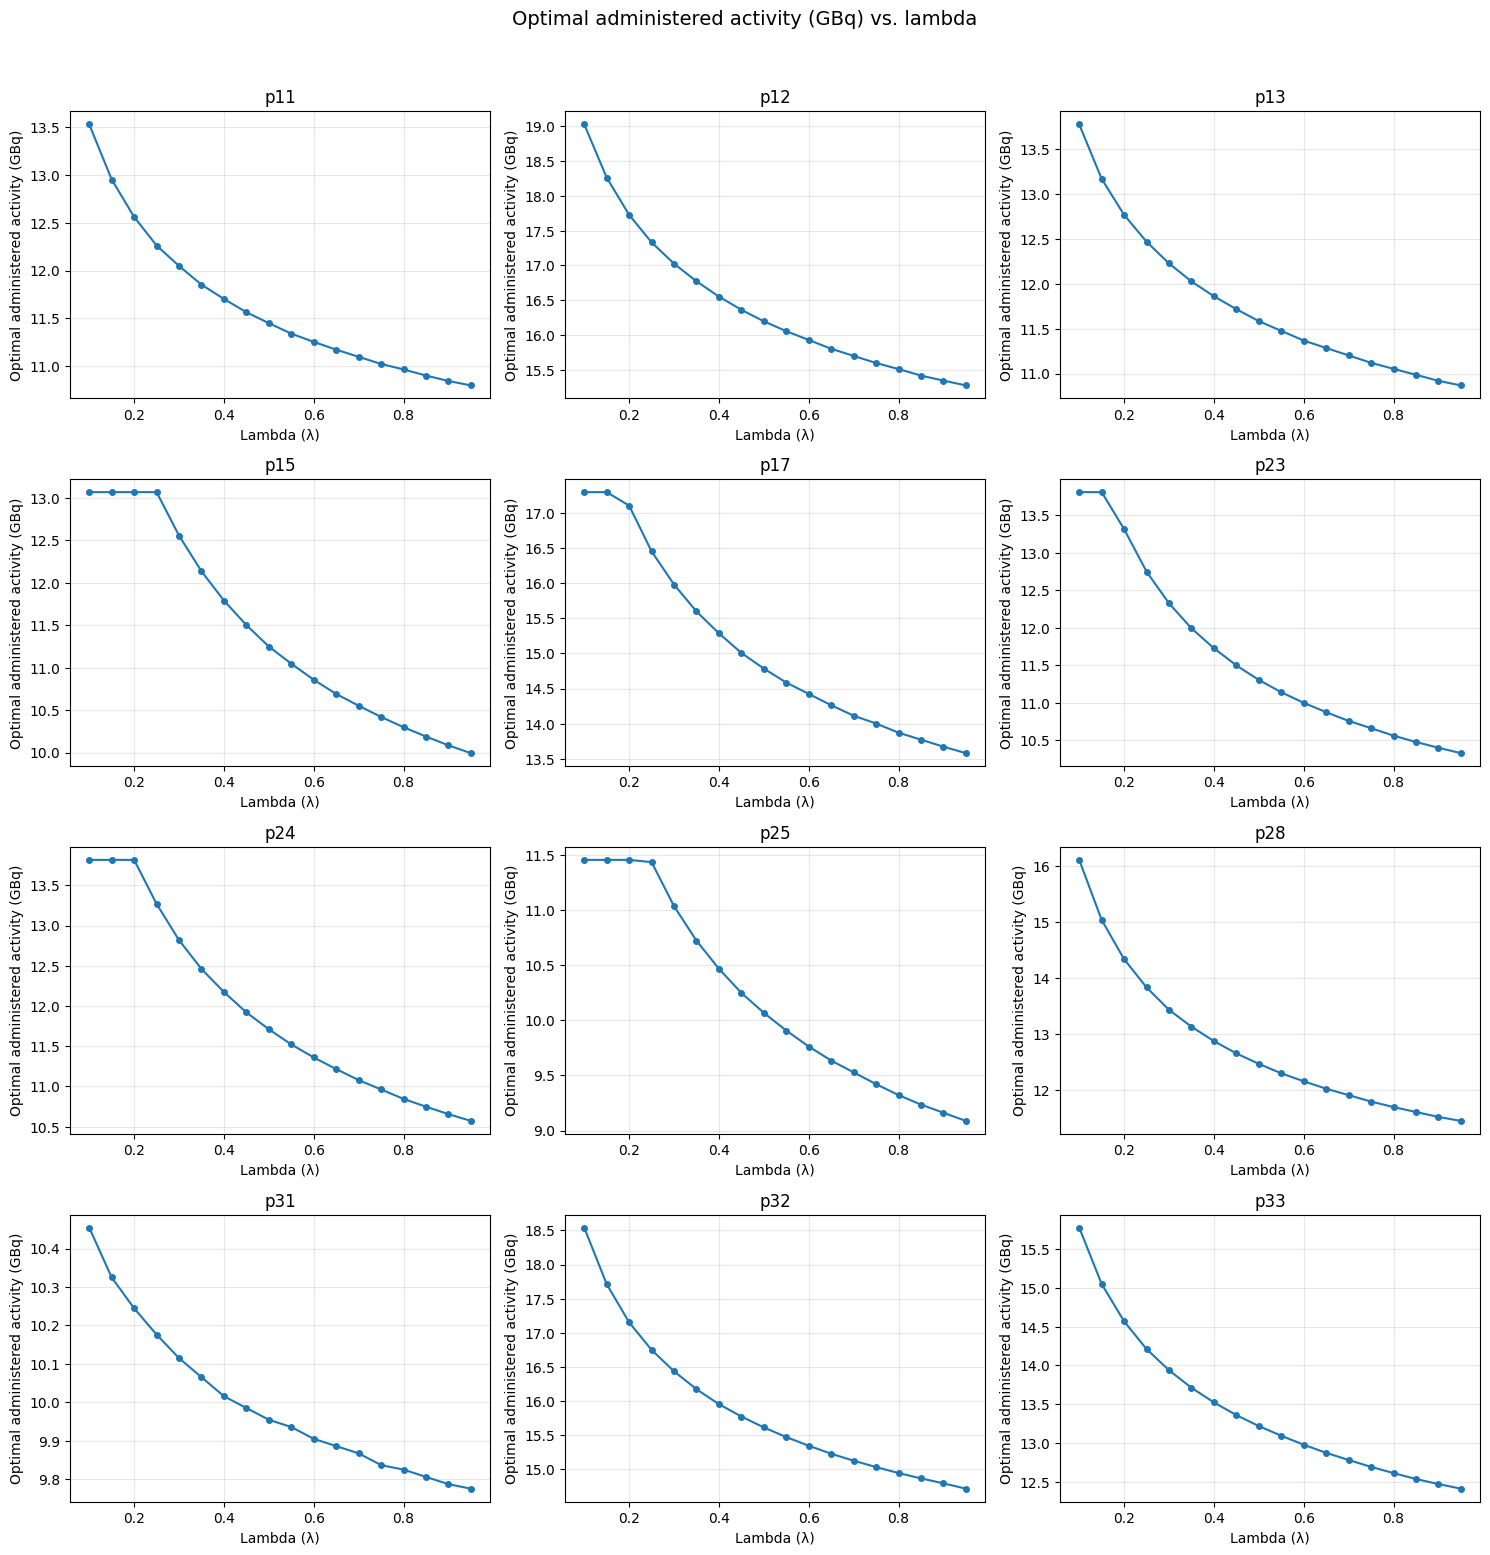

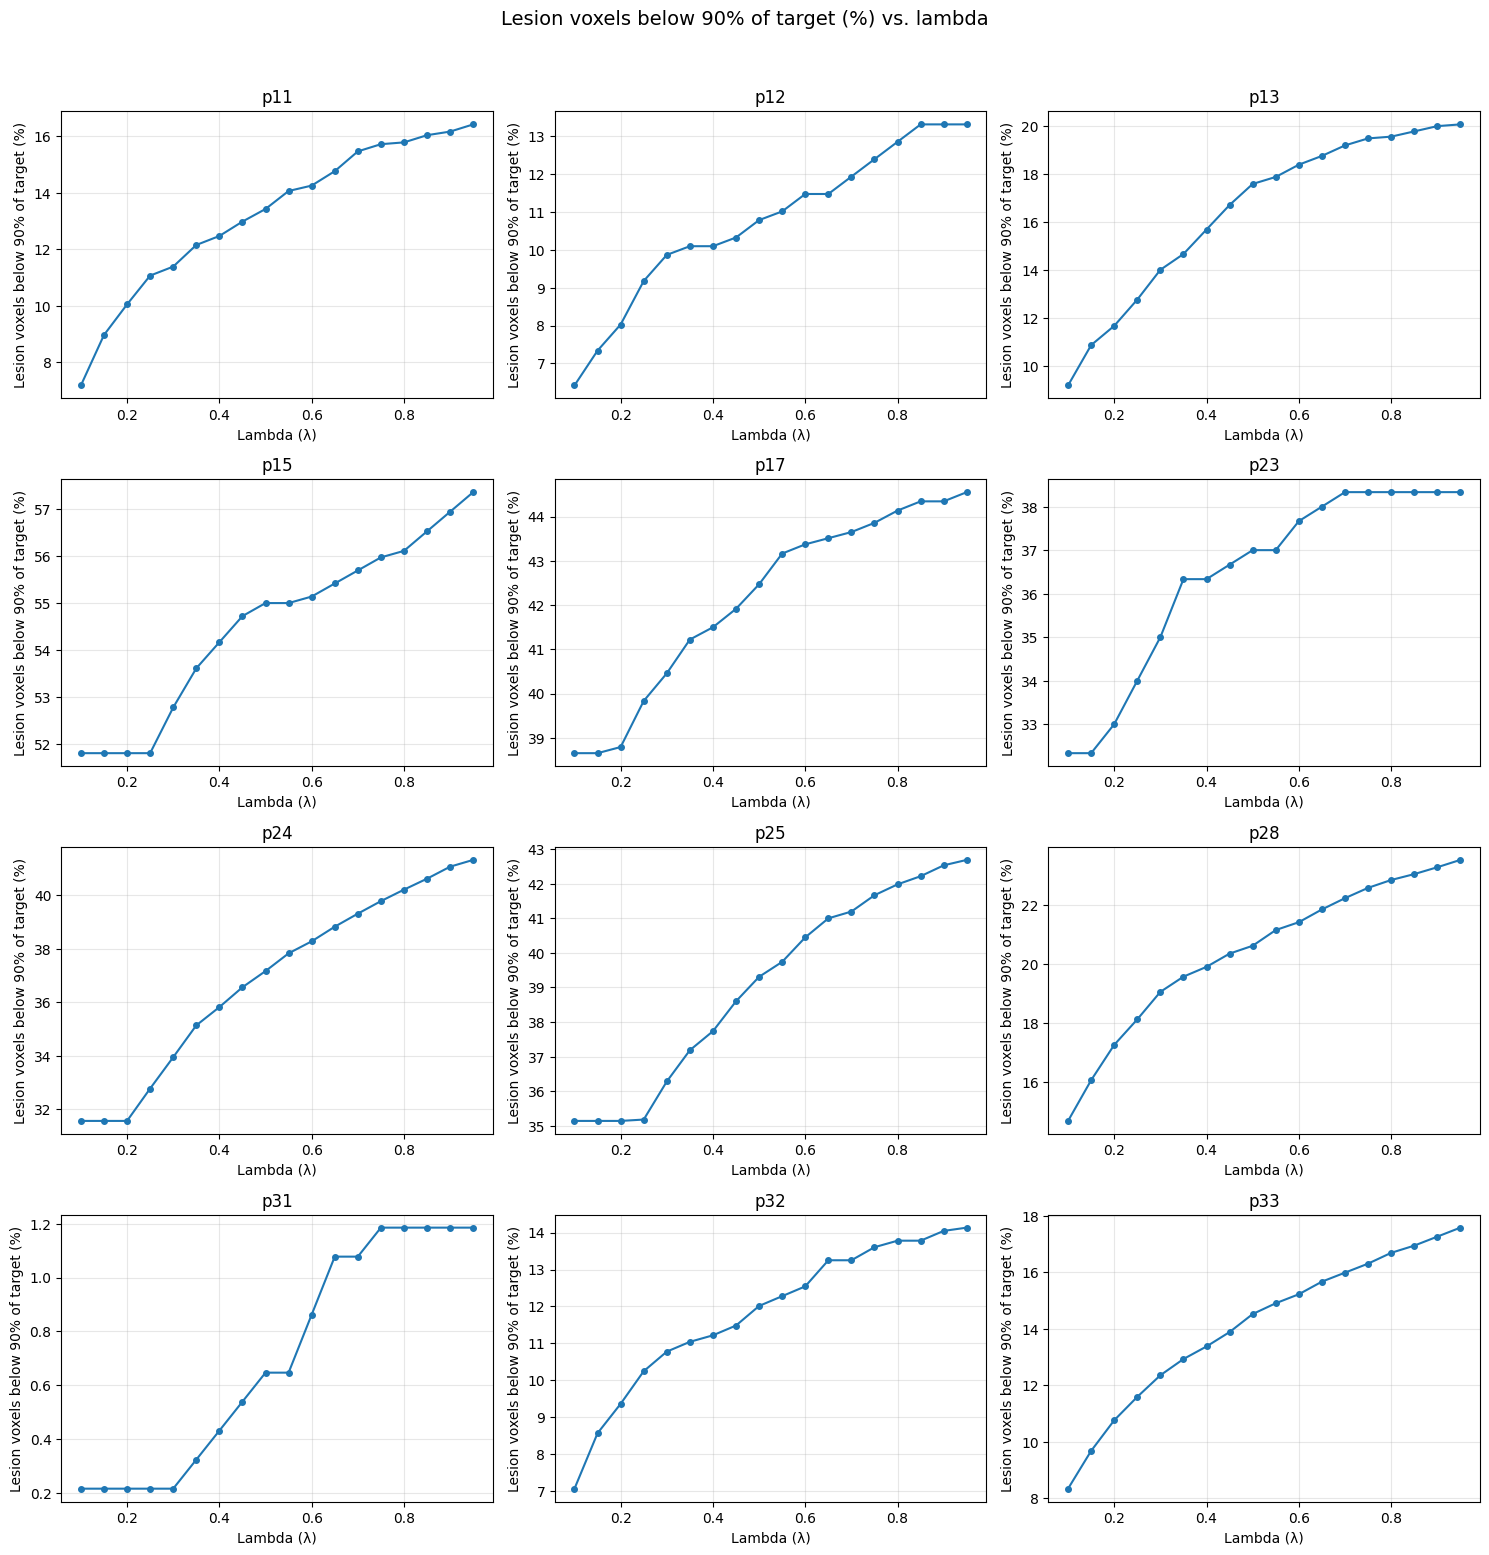

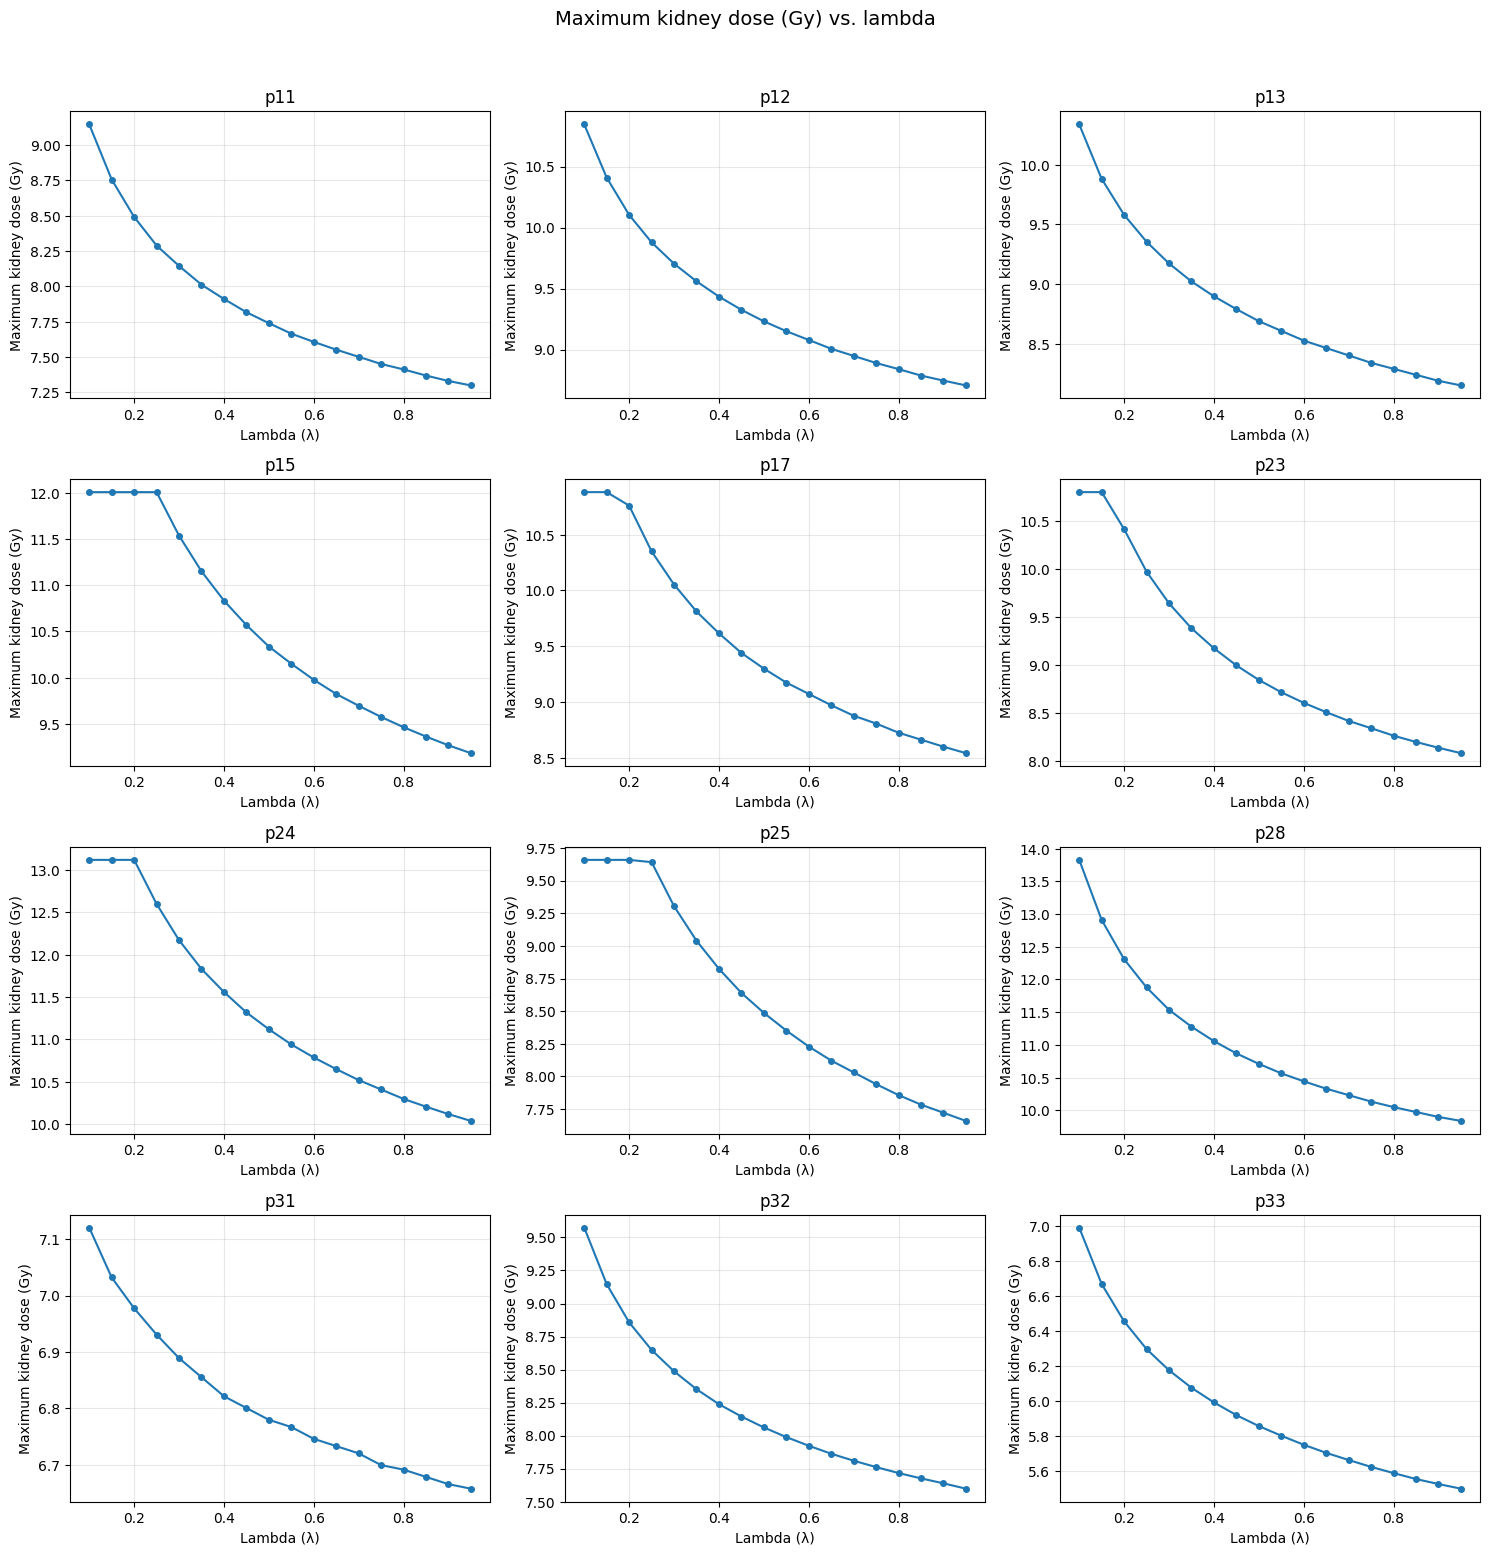

In [3]:
patients=["p11","p15", "p24", "p32", "p33", "p17", "p23", "p25",  "p28","p31", "p13", "p12"]
all_patient_results = []

kidney_thresh = 5
for patient in patients:
    abdose_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    spect_24h_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_lu177.nii"
    seg_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    df_patient= optimisation_activity.main_evaluation_lambda(abdose_path, seg_path, 
                        spect_24h_path, 7400,tumours[patient], patient, kidney_thresh= kidney_thresh)
    all_patient_results.append(df_patient)
    
results_df = pd.concat(all_patient_results, ignore_index=True)
pd.set_option("display.max_columns", None)
print(results_df.round(3).to_string(index=False))

def plot_lambda(results_df, ncols=3, save_figures=False):

    metrics = [("best_activity_GBq", "Optimal administered activity (GBq)"),
        ("cold_below_90", "Lesion voxels below 90% of target (%)"),
        ("kidney_2_max_Gy", "Maximum kidney dose (Gy)")]

    patients = sorted(results_df["patient"].unique())
    for column, ylabel in metrics:
        if column not in results_df.columns:
            print(f"Skipping {column}: column not found.")
            continue
        nrows = math.ceil(len(patients) / ncols)
        fig, axes = plt.subplots(nrows, ncols,figsize=(5 * ncols, 3.8 * nrows),squeeze=False)
        axes = axes.flatten()
        for i, patient in enumerate(patients):
            ax = axes[i]
            df = (results_df[results_df["patient"] == patient].sort_values("lambda"))
            
            ax.plot(df["lambda"],df[column],marker="o",markersize=4,linewidth=1.5)
            ax.set_title(patient)
            ax.set_xlabel("Lambda (λ)")
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)

        for j in range(len(patients), len(axes)):
            axes[j].set_visible(False)
        fig.suptitle(f"{ylabel} vs. lambda",fontsize=14,y=1.02)
        fig.tight_layout()

        if save_figures:
            filename = f"{column}_vs_lambda.png"
            fig.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()

plot_lambda(results_df, ncols=3, save_figures=True)

knee: lambda = 0.55 | coverage = 74.6% | kidney max = 6.17 Gy


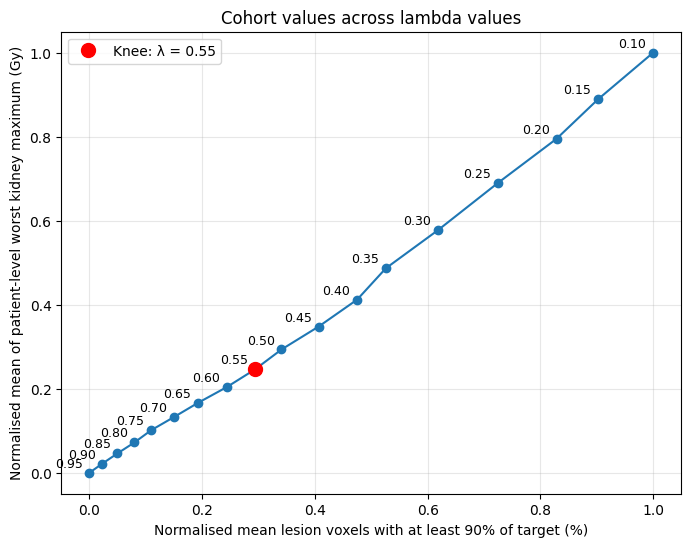

In [4]:
optimisation_activity.choose_lambda(results_df)

In [ ]:
def plot_lambda_tradeoff(summary, results, spread_lams=(0.1, 0.3, 0.5, 0.7, 1.0, 1.5),
                         midlines=True, savepath=None):
    """
    summary : DataFrame with 'lambda', 'cold90_mean', 'kidney_max_mean' (cohort means per lambda)
    results : DataFrame, one row per (patient, lambda): 'patient', 'lambda', 'cold90', 'kidney_max'
    spread_lams : lambdas that get a patient-spread cross (None = all)
    """
    s = summary.sort_values("lambda").copy()
    s["coverage90_mean"] = 100 - s["cold90_mean"]
    x_raw = s["coverage90_mean"].values
    y_raw = s["kidney_max_mean"].values
    lam = s["lambda"].values

    x = (x_raw - x_raw.min()) / (x_raw.max() - x_raw.min())
    y = (y_raw - y_raw.min()) / (y_raw.max() - y_raw.min())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    ax1.plot(x, y, marker="o")
    ax1.axhline(0.5, ls="--", color="grey", alpha=0.7)
    ax1.axvline(0.5, ls="--", color="grey", alpha=0.7)
    for l, xi, yi in zip(lam, x, y):
        ax1.annotate(f"{l:.1f}", (xi, yi), xytext=(-10, 4), textcoords="offset points", fontsize=9)
    ax1.set_xlabel("Mean lesion voxels with ≥90% of target (normalised)")
    ax1.set_ylabel("Mean of patient-level worst kidney maximum (normalised)")
    ax1.set_title("Normalised")
    ax1.grid(alpha=0.3)

    ax2.plot(x_raw, y_raw, marker="o", zorder=3, label="Cohort mean")
    if midlines:   # same positions as the 0.5 lines on the left
        ax2.axhline((y_raw.min() + y_raw.max()) / 2, ls="--", color="grey", alpha=0.7)
        ax2.axvline((x_raw.min() + x_raw.max()) / 2, ls="--", color="grey", alpha=0.7)
    for l, xi, yi in zip(lam, x_raw, y_raw):
        ax2.annotate(f"{l:.1f}", (xi, yi), xytext=(-10, 4), textcoords="offset points", fontsize=9)

    res = results.copy()
    res["lambda"] = res["lambda"].round(2)
    res["coverage90"] = 100 - res["cold_below_90"]
    chosen = lam if spread_lams is None else [l for l in lam if np.any(np.isclose(spread_lams, l))]
    for l in chosen:
        g = res[np.isclose(res["lambda"], l)]
        xq = np.percentile(g["coverage90"], [25, 50, 75])
        yq = np.percentile(g["kidney_worst_max_Gy"], [25, 50, 75])
        ax2.plot([xq[0], xq[2]], [yq[1], yq[1]], color="tab:orange", lw=2, alpha=0.7, zorder=2)
        ax2.plot([xq[1], xq[1]], [yq[0], yq[2]], color="tab:orange", lw=2, alpha=0.7, zorder=2)
    ax2.plot([], [], color="tab:orange", lw=2, label="Patient IQR (cross at median)")
    ax2.legend(loc="best", fontsize=8)

    ax2.set_xlabel("Mean lesion voxels with ≥90% of target (%)")
    ax2.set_ylabel("Mean of patient-level worst kidney maximum (Gy)")
    ax2.set_title("Real units, with patient spread")
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300)
    plt.show()

plot_lambda_tradeoff(summary, df)